In [28]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

In [15]:
df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


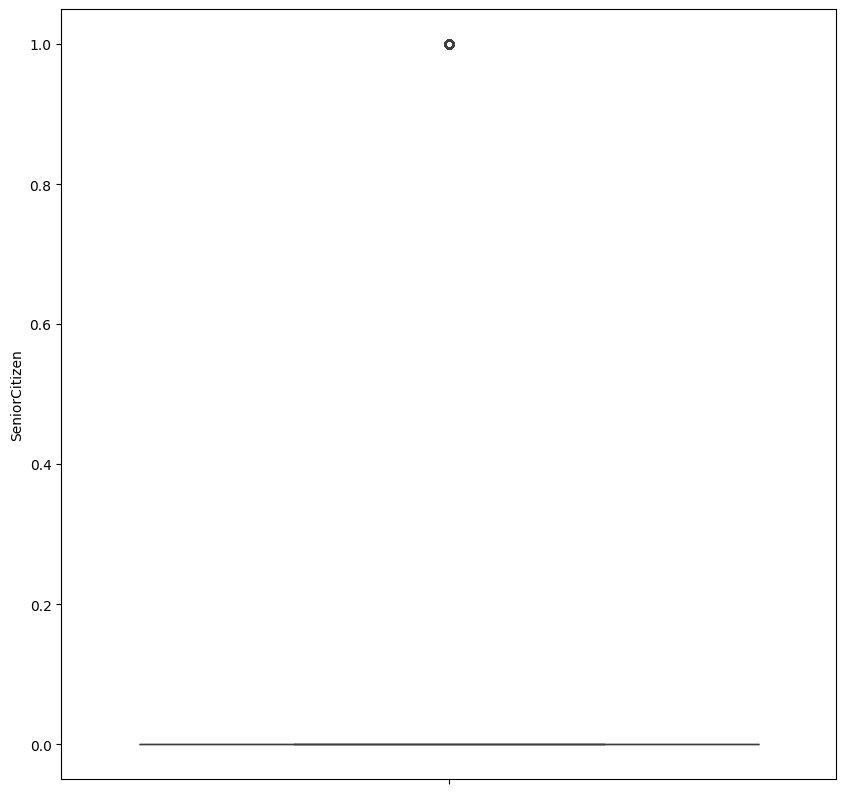

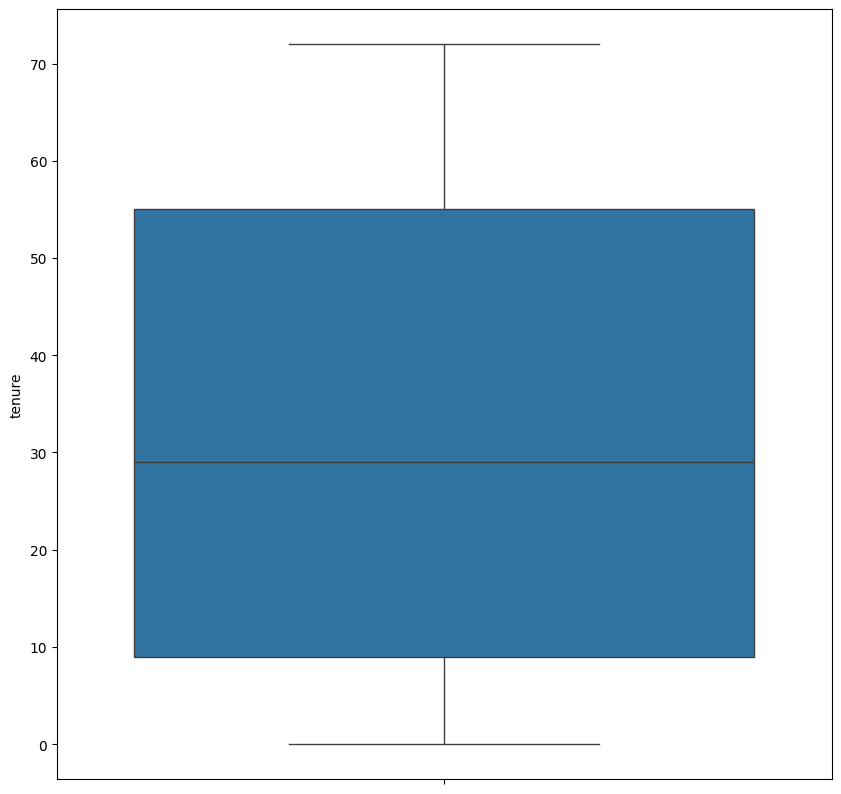

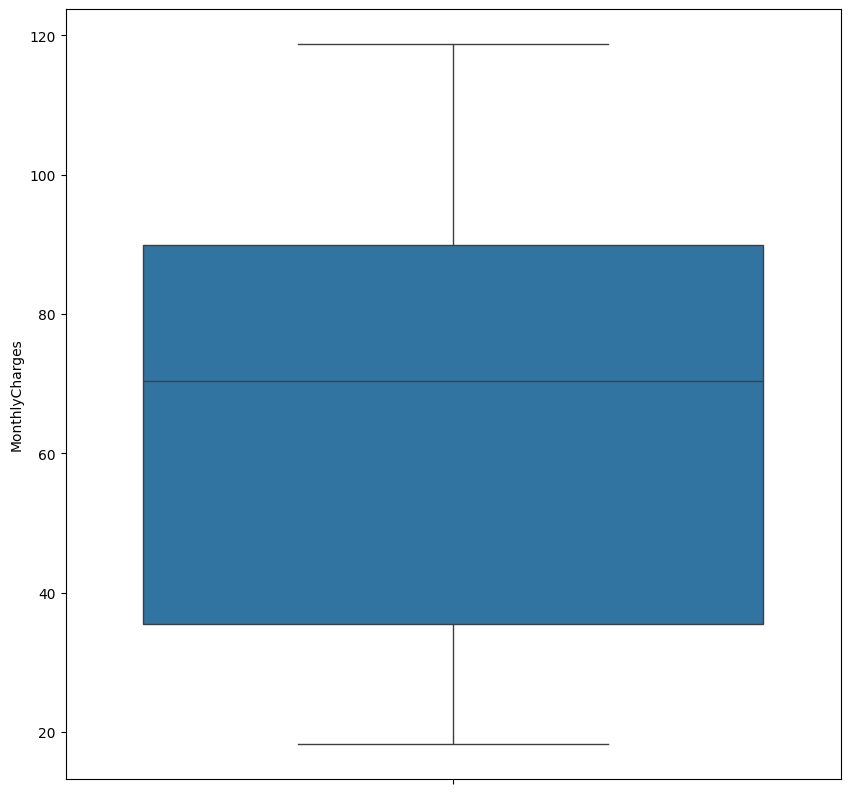

In [8]:
for i in ['SeniorCitizen','tenure','MonthlyCharges']:
  plt.figure(figsize=(10,10))
  sns.boxplot(df[i])
  plt.show()

In [9]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [10]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [23]:
X = df.drop('Churn', axis=1)

In [24]:
Y= df['Churn'].map({"Yes":1,"No": 0})

In [30]:
x_train, x_test, y_train,y_test = train_test_split(X,Y,test_size=0.2,random_state=42,stratify=Y)

In [33]:
import numpy as np

categorical_cols = x_train.select_dtypes(include=['object']).columns

for df_temp in [x_train, x_test]:
    df_temp['TotalCharges'] = pd.to_numeric(df_temp['TotalCharges'].replace(' ', np.nan))
    df_temp['TotalCharges'] = df_temp['TotalCharges'].fillna(0)

categorical_cols = x_train.select_dtypes(include=['object']).columns

le_dict = {}
for col in categorical_cols:
    if col == 'customerID':
        x_train = x_train.drop(columns=['customerID'])
        x_test = x_test.drop(columns=['customerID'])
        continue

    le = LabelEncoder()
    x_train[col] = le.fit_transform(x_train[col])
    x_test[col] = le.transform(x_test[col])
    le_dict[col] = le

# Verify the encoding
display(x_train.head())

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
3738,1,0,0,0,35,0,1,0,0,0,2,0,2,2,0,0,2,49.20,1701.65
3151,1,0,1,1,15,1,0,1,2,0,0,0,0,0,0,0,3,75.10,1151.55
4860,1,0,1,1,13,0,1,0,2,2,0,2,0,0,2,0,3,40.55,590.35
3867,0,0,1,0,26,1,0,0,0,2,2,0,2,2,2,1,1,73.50,1905.70
3810,1,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,2,44.55,44.55


In [34]:
import pandas as pd
from sklearn.model_selection import cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

results = []

baseline_dt = DecisionTreeClassifier(random_state=42)


cv_scores = cross_val_score(baseline_dt, x_train, y_train, cv=5, scoring='accuracy')
print(f"Baseline Decision Tree 5-Fold CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

baseline_dt.fit(x_train, y_train)
y_pred_base = baseline_dt.predict(x_test)
base_acc = accuracy_score(y_test, y_pred_base)
base_f1 = f1_score(y_test, y_pred_base, average='macro')

results.append({
    'Model': 'Baseline Decision Tree',
    'CV Accuracy (Mean)': f"{cv_scores.mean():.4f}",
    'Test Accuracy': base_acc,
    'Test F1 (Macro)': base_f1
})

param_grid = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(x_train, y_train)
best_grid_dt = grid_search.best_estimator_

y_pred_grid = best_grid_dt.predict(x_test)
grid_acc = accuracy_score(y_test, y_pred_grid)
grid_f1 = f1_score(y_test, y_pred_grid, average='macro')

results.append({
    'Model': 'GridSearchCV (Decision Tree)',
    'CV Accuracy (Mean)': f"{grid_search.best_score_:.4f}",
    'Test Accuracy': grid_acc,
    'Test F1 (Macro)': grid_f1
})
print(f"GridSearchCV Best Params: {grid_search.best_params_}")

param_dist = {
    'max_depth': [3, 5, 7, 10, 15, None],
    'min_samples_split': range(2, 20),
    'min_samples_leaf': range(1, 10)
}

random_search = RandomizedSearchCV(DecisionTreeClassifier(random_state=42), param_distributions=param_dist,
                                   n_iter=20, cv=5, scoring='accuracy', random_state=42, n_jobs=-1)
random_search.fit(x_train, y_train)
best_random_dt = random_search.best_estimator_

y_pred_rand = best_random_dt.predict(x_test)
rand_acc = accuracy_score(y_test, y_pred_rand)
rand_f1 = f1_score(y_test, y_pred_rand, average='macro')

results.append({
    'Model': 'RandomizedSearchCV (Decision Tree)',
    'CV Accuracy (Mean)': f"{random_search.best_score_:.4f}",
    'Test Accuracy': rand_acc,
    'Test F1 (Macro)': rand_f1
})
print(f"RandomizedSearchCV Best Params: {random_search.best_params_}")

rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_cv_scores = cross_val_score(rf_model, x_train, y_train, cv=5, scoring='accuracy')

rf_model.fit(x_train, y_train)
y_pred_rf = rf_model.predict(x_test)
rf_acc = accuracy_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf, average='macro')

results.append({
    'Model': 'Random Forest (Ensemble)',
    'CV Accuracy (Mean)': f"{rf_cv_scores.mean():.4f}",
    'Test Accuracy': rf_acc,
    'Test F1 (Macro)': rf_f1
})

summary_df = pd.DataFrame(results)
display(summary_df)

Baseline Decision Tree 5-Fold CV Accuracy: 0.7362 (+/- 0.0094)
GridSearchCV Best Params: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2}
RandomizedSearchCV Best Params: {'min_samples_split': 9, 'min_samples_leaf': 7, 'max_depth': 5}


,Model,CV Accuracy (Mean),Test Accuracy,Test F1 (Macro)
0,Baseline Decision Tree,0.7362,0.728886,0.658131
1,GridSearchCV (Decision Tree),0.7916,0.784954,0.716594
2,RandomizedSearchCV (Decision Tree),0.7895,0.784954,0.720653
3,Random Forest (Ensemble),0.7868,0.794890,0.717347
